# Building Agentic Workflows with LangGraph

LangGraph is a framework from LangChain for controlling the flow of an LLM application. LangChain gives you a standard interface to models, retrieval and tool calls; LangGraph gives you the structure that decides what runs next. They are separate packages and can be used alone, though most projects use both.

## Control vs Freedom

Every AI application trades freedom against control.

**Freedom** lets the LLM improvise. Code agents like smolagents can call several tools in one step and write their own -- creative, but hard to predict and hard to guardrail.

**Control** keeps behaviour predictable and keeps guardrails intact.

LangGraph sits at the control end. If your application is a series of steps that must run in a specific order, with a decision at each junction, LangGraph is the structure for it. Reach for it when you need multi-step reasoning with explicit control, state that persists between steps, deterministic logic mixed with AI, human-in-the-loop intervention, or several components orchestrated together.

You could build the same thing with plain Python `if`/`else`. LangGraph earns its place with what surrounds it: state management, visualization, tracing and built-in human-in-the-loop.

## Building Blocks

A LangGraph application starts at an entrypoint and flows node to node until it reaches `END`.

**State** -- a `TypedDict` holding everything the application needs in order to make decisions. The fields are user-defined, so craft them carefully; this is the data every node reads and writes.

**Nodes** -- plain Python functions. Each one takes the state, does a single thing, and returns updates to the state. A node can call an LLM, call a tool, apply conditional logic, or ask a human.

**Edges** -- connect nodes and define the possible paths. A *direct* edge always goes from A to B. A *conditional* edge reads the current state and picks the next node.

**StateGraph** -- the container that holds the workflow. Add nodes, wire the edges, then `compile()` it into something you can invoke.

`START` and `END` are provided by LangGraph itself.

In [2]:
!uv add langgraph langchain-openai

Resolved 405 packages in 8ms
Audited 376 packages in 105ms


In [3]:
from dotenv import load_dotenv
load_dotenv()

import random
from typing import Literal
from typing_extensions import TypedDict

from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

## A First Graph

The wiring only, with no LLM involved.

In [4]:
class State(TypedDict):
    itinerary: str


def search_flights(state):
    print("---Search flights---")
    return {"itinerary": state["itinerary"] + " [searched]"}


def book_direct(state):
    print("---Book direct---")
    return {"itinerary": state["itinerary"] + " [direct]"}


def book_connecting(state):
    print("---Book connecting---")
    return {"itinerary": state["itinerary"] + " [connecting]"}


def decide_route(state) -> Literal["book_direct", "book_connecting"]:
    # often the state decides which node runs next -- here it is a 50/50 split
    if random.random() < 0.5:
        return "book_direct"
    return "book_connecting"

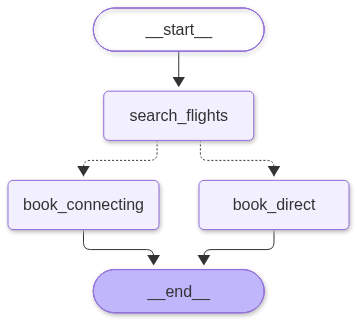

---Search flights---
---Book connecting---


{'itinerary': 'Nairobi to Mombasa [searched] [connecting]'}

In [5]:
builder = StateGraph(State)

builder.add_node("search_flights", search_flights)
builder.add_node("book_direct", book_direct)
builder.add_node("book_connecting", book_connecting)

builder.add_edge(START, "search_flights")
builder.add_conditional_edges("search_flights", decide_route)
builder.add_edge("book_direct", END)
builder.add_edge("book_connecting", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

graph.invoke({"itinerary": "Nairobi to Mombasa"})

## Booking Request Workflow

A real graph: a customer sends a booking request, the agent checks whether it holds everything needed to search for flights, and the flow branches -- incomplete requests go back for missing details, complete ones get a drafted quote.

In [6]:
class BookingState(TypedDict):
    request: dict                # name, origin, destination, dates, passengers
    trip_type: str | None        # one-way, round-trip
    missing_fields: str | None   # what the request is missing
    is_complete: bool | None
    quote: str | None
    messages: list               # the LLM exchange, for tracking

In [7]:
model = ChatOpenAI(model="gpt-5-nano")


def read_request(state: BookingState):
    """The agent logs the incoming booking request."""
    request = state["request"]
    print(f"Booking request from {request['name']}: {request['origin']} to {request['destination']}")
    return {}


def analyze_request(state: BookingState):
    """The agent checks whether the request has everything needed to book."""
    request = state["request"]

    prompt = f"""
    You are a flight booking agent. Check whether this booking request has everything
    needed to search and book a flight.

    Name: {request['name']}
    Origin: {request['origin']}
    Destination: {request['destination']}
    Departure: {request['date'] or '(none given)'}
    Return: {request['return_date'] or '(none given)'}
    Passengers: {request['passengers']}

    A usable request needs origin, destination, departure date and number of passengers.
    A trip with a return date is round-trip; otherwise it is one-way.

    Reply with exactly these three lines:
    Status: complete or incomplete
    Missing: what is missing (or none)
    Trip: one-way or round-trip
    """

    response = model.invoke([HumanMessage(content=prompt)])

    lines = response.content.lower().splitlines()

    def field(prefix):
        for line in lines:
            if line.strip().startswith(prefix):
                return line.split(":", 1)[1].strip()
        return None

    status = field("status") or ""
    is_complete = "incomplete" not in status and "complete" in status

    missing_fields = field("missing")
    if missing_fields in (None, "none"):
        missing_fields = None

    trip_type = field("trip")

    new_messages = state.get("messages", []) + [
        {"role": "user", "content": prompt},
        {"role": "assistant", "content": response.content},
    ]

    return {
        "is_complete": is_complete,
        "missing_fields": missing_fields,
        "trip_type": trip_type,
        "messages": new_messages,
    }

In [8]:
def request_details(state: BookingState):
    """The agent reports what the request is missing."""
    print(f"Booking request is incomplete. Missing: {state['missing_fields']}")
    print("Please supply the missing details so we can search for flights.")
    return {}


def quote_flight(state: BookingState):
    """The agent drafts a price quote for the confirmed itinerary."""
    request = state["request"]
    trip = state["trip_type"] or "one-way"

    prompt = f"""
    You are a flight booking agent. Draft a short, professional reply quoting this trip.

    Name: {request['name']}
    Origin: {request['origin']}
    Destination: {request['destination']}
    Departure: {request['date']}
    Passengers: {request['passengers']}
    Trip: {trip}

    Give a brief quote the customer can review before anything is confirmed.
    Keep it under 80 words and invent plausible airline names and prices.
    """

    response = model.invoke([HumanMessage(content=prompt)])

    new_messages = state.get("messages", []) + [
        {"role": "user", "content": prompt},
        {"role": "assistant", "content": response.content},
    ]

    return {"quote": response.content, "messages": new_messages}


def notify_customer(state: BookingState):
    """The agent reports the itinerary and the draft quote."""
    request = state["request"]

    print("\n" + "=" * 50)
    print(f"{request['name']}, here is your quote for {request['origin']} to {request['destination']}.")
    print(f"Departure: {request['date']} | Passengers: {request['passengers']} | Trip: {state['trip_type']}")
    print("\nDraft reply ready for review:")
    print("-" * 50)
    print(state["quote"])
    print("=" * 50 + "\n")
    return {}

In [9]:
def route_request(state: BookingState) -> str:
    """Send complete requests to quoting, incomplete ones back to the customer."""
    return "complete" if state["is_complete"] else "incomplete"


booking_graph = StateGraph(BookingState)

booking_graph.add_node("read_request", read_request)
booking_graph.add_node("analyze_request", analyze_request)
booking_graph.add_node("request_details", request_details)
booking_graph.add_node("quote_flight", quote_flight)
booking_graph.add_node("notify_customer", notify_customer)

booking_graph.add_edge(START, "read_request")
booking_graph.add_edge("read_request", "analyze_request")

booking_graph.add_conditional_edges(
    "analyze_request",
    route_request,
    {"incomplete": "request_details", "complete": "quote_flight"},
)

booking_graph.add_edge("request_details", END)
booking_graph.add_edge("quote_flight", "notify_customer")
booking_graph.add_edge("notify_customer", END)

compiled_graph = booking_graph.compile()

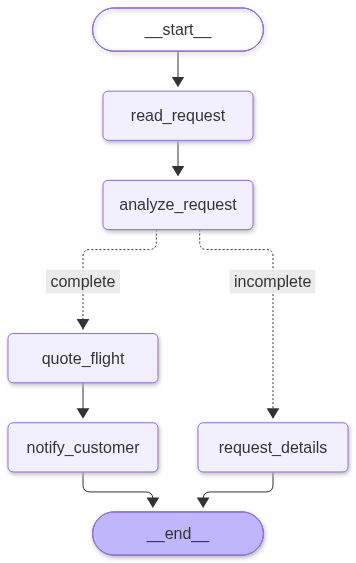

In [10]:
display(Image(compiled_graph.get_graph().draw_mermaid_png()))

In [11]:
complete_request = {
    "name": "Amina Otieno",
    "origin": "Nairobi",
    "destination": "Mombasa",
    "date": "2026-11-14",
    "return_date": "2026-11-21",
    "passengers": 2,
}

incomplete_request = {
    "name": "James Kariuki",
    "origin": "Nairobi",
    "destination": "Kigali",
    "date": "",
    "return_date": "",
    "passengers": 1,
}

initial_state = {
    "trip_type": None,
    "missing_fields": None,
    "is_complete": None,
    "quote": None,
    "messages": [],
}

print("\nProcessing complete request...")
complete_result = compiled_graph.invoke({**initial_state, "request": complete_request})

print("\nProcessing incomplete request...")
incomplete_result = compiled_graph.invoke({**initial_state, "request": incomplete_request})


Processing complete request...
Booking request from Amina Otieno: Nairobi to Mombasa

Amina Otieno, here is your quote for Nairobi to Mombasa.
Departure: 2026-11-14 | Passengers: 2 | Trip: round-trip

Draft reply ready for review:
--------------------------------------------------
Hello Amina Otieno, here is your quote: Nairobi (NBO) to Mombasa (MBA), outbound 14 Nov 2026, round-trip for 2. Carrier: Coastal Skyways. Fare: $165 per person, taxes included. Estimated total: $330. Return date to be confirmed. Baggage: 7kg carry-on per passenger. Availability and price hold for 24 hours.


Processing incomplete request...
Booking request from James Kariuki: Nairobi to Kigali
Booking request is incomplete. Missing: departure date
Please supply the missing details so we can search for flights.
